# v8 environment-option results (Oct 31 - Nov 1, 2026)

All eg15 PPO runs on the v8 preview (frozen v7 core plus environment knobs, `variants/v8`):

| Study | Launched | What it tests |
|---|---|---|
| 512M wave | Oct 31 evening | one environment factor at a time (ore, trees, view, episode length) |
| 2B wave | Oct 31 night | best variants at 2B; width, LSTM, frontier shaping; larger world |
| overnight | Nov 1 night | 1% uniform mixing, log-scale inventory, frontier combinations, more seeds, 4B |
| Nov 1 morning | Nov 1 07:20 EST | frontier coefficient 10, frontier-surface, no-shaping controls, larger world / view |
| discount | Nov 1 10:00 EST | gamma .9995 / .9998 on the best shaped and best generic arms |
| long runs | Nov 1 10:00 EST | larger world (default ore) and view 21x15 at 4B, larger-world LSTM |
| Go-Explore | Nov 1 13:35 EST | archive restarts from the policy's own states |
| final 5 seeds | Nov 1 15:10 EST | seeds 2003-2005 for the final configurations (5 seeds each) |
| gamma .9998 at 4B | Nov 1 17:25 EST | best shaped and generic arms at 4B (first iron pickaxe: best shaped, seed 2001) |
| gamma .9999 | Nov 1 ~19:00 EST | generic arm at gamma .9999, 2B |

The final configurations were also evaluated once on the reserved test worlds (25,000,001-25,000,128):
`test.json` next to each run's `curve.json` (Part 3).

Each run directory holds `curve.json` (validation at every checkpoint), `summary.json`, `protocol.json`
(full training config) and `diag.json` (stockpiling diagnostic on the final checkpoint). All evaluations
use the same 128 validation worlds (23,000,001-23,000,128); scores are achievements out of 32.
Unfinished runs show their latest checkpoint.

Open from the repo root with pandas and matplotlib, e.g.

    uv run --no-project --with pandas,matplotlib,jupyterlab jupyter lab notebooks/v8_env_results_2026_10_31.ipynb

Refresh data from eg15 (curves, summaries, protocols, diagnostics only), per study directory:

    rsync -a -e "ssh -J decidueye" --include='*/' --include='curve.json' --include='summary.json' \
      --include='protocol.json' --include='diag.json' --exclude='*' \
      mvohl@cv350-rck-g03-c01-08.rck.dcgpu:Projects/RL/experiments/<study>/ experiments/eg15/<study>/

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

ROOT = Path("..") if Path("../experiments/eg15").exists() else Path(".")
DATA = ROOT / "experiments/eg15"
STUDIES = {  # label -> directory under DATA; add new studies here
    "512M wave": "eg15-envopt-v7-20261027",
    "2B wave": "eg15-envopt2b-v8-20261101",
    "overnight": "eg15-overnight-v8-20261101",
    "Nov 1 morning": "eg15-queue-v8-20261101b",
    "discount": "eg15-gamma-v8-20261101c",
    "long runs": "eg15-long-v8-20261101c",
    "Go-Explore": "eg15-goexplore-v8-20261101e",
    "final 5 seeds": "eg15-final5-v8-20261101f",
    "gamma .9998 at 4B": "eg15-4b-v8-20261101g",
    "gamma .9999": "eg15-g9999-v8-20261101g",
}
# Environment knobs per library build (variants/v8/README.md). Defaults reproduce v7.
LIBS = {
    "build-v8":                {"ore %": 100, "trunk %": 100, "view": "11x9",  "world": "128x96", "log inventory": False},
    "build-v8-ore200":         {"ore %": 200, "trunk %": 100, "view": "11x9",  "world": "128x96", "log inventory": False},
    "build-v8-ore300":         {"ore %": 300, "trunk %": 100, "view": "11x9",  "world": "128x96", "log inventory": False},
    "build-v8-tree200":        {"ore %": 100, "trunk %": 200, "view": "11x9",  "world": "128x96", "log inventory": False},
    "build-v8-ore300-tree200": {"ore %": 300, "trunk %": 200, "view": "11x9",  "world": "128x96", "log inventory": False},
    "build-v8-view21":         {"ore %": 100, "trunk %": 100, "view": "21x15", "world": "128x96", "log inventory": False},
    "build-v8-real":           {"ore %": 300, "trunk %": 200, "view": "21x15", "world": "128x96", "log inventory": False},
    "build-v8-o3t2-inv":       {"ore %": 300, "trunk %": 200, "view": "11x9",  "world": "128x96", "log inventory": True},
    "build-v8-real-inv":       {"ore %": 300, "trunk %": 200, "view": "21x15", "world": "128x96", "log inventory": True},
    "build-v8-w256":           {"ore %": 100, "trunk %": 100, "view": "11x9",  "world": "256x96", "log inventory": False},
    "build-v8-w256-o3t2":      {"ore %": 300, "trunk %": 200, "view": "11x9",  "world": "256x96", "log inventory": False},
}
ACHIEVEMENTS = ["collect wood", "collect stone", "place block", "craft workbench", "craft furnace", "craft anvil", "place torch", "place platform", "collect copper", "collect iron", "collect silver", "collect gold", "smelt copper", "smelt iron", "smelt silver", "smelt gold", "defeat Blue Slime", "defeat Cave Bat", "open chest", "craft wooden sword", "craft metal sword", "craft wood breastplate", "craft iron chainmail", "heal with food or potion", "use life crystal", "double jump", "descend deep", "return to surface", "explore 30 columns", "climb rope", "craft iron pickaxe", "craft gold pickaxe"]  # SPEC.achievement_names (v7/v8)
HARD = ["craft anvil", "craft metal sword", "craft iron pickaxe", "craft gold pickaxe",
        "craft iron chainmail", "craft wood breastplate", "return to surface"]
# Queue files map job names to library builds (runs launched by tools/gpu_queue.py).
JOB_LIB = {j["name"]: j["lib"] for q in (ROOT / "tools").glob("*queue*.json") for j in json.loads(q.read_text())}
JOB_LIB["view21_4B-g7"] = "build-v8-view21"   # launched by hand next to the Nov 1 morning queue

In [2]:
def lib_of(group_dir: str) -> str:
    if group_dir in JOB_LIB:
        return JOB_LIB[group_dir]
    head, _, tail = group_dir.rpartition("-")          # wave dirs: build-v8-xxx or build-v8-xxx-g3
    return head if tail.startswith("g") and tail[1:].isdigit() else group_dir

def variant_label(k: dict) -> str:
    parts = []
    if k["world"] != "128x96": parts.append(f"world {k['world']}")
    if k["ore %"] != 100: parts.append(f"ore {k['ore %'] // 100}x")
    if k["trunk %"] != 100: parts.append(f"trees {k['trunk %'] // 100}x")
    if k["view"] != "11x9": parts.append(f"view {k['view']}")
    if k["log inventory"]: parts.append("log inventory")
    return " + ".join(parts) or "v8 default (= v7)"

def arm_label(c: dict) -> str:
    shaping = "no shaping" if not c["potential_coef"] else \
        f"pot {c['potential_coef']:g}" + (f" {c['potential_mode']}" if c["potential_mode"] != "mean" else "")
    parts = [shaping]
    if c.get("novelty_coef"): parts.append(f"novelty {c['novelty_coef']:g}")
    if c.get("unimix"): parts.append(f"unimix {c['unimix']:g}")
    if c.get("archive_start_prob"): parts.append(f"Go-Explore {c['archive_start_prob']:g}")
    if c.get("memory"): parts.append(f"{c['memory']} {c.get('memory_size') or 256}")
    if c.get("hidden"): parts.append(f"hidden {c['hidden']}")
    if c.get("lr") != 3e-4: parts.append(f"lr {c['lr']:g}")
    if c.get("gamma") != 0.999: parts.append(f"gamma {c['gamma']:g}")
    if c.get("episode_steps"): parts.append(f"{c['episode_steps']} steps/ep")
    return ", ".join(parts)

def crafter_score(hits: dict, episodes: int) -> float:
    """Crafter's headline metric: geometric mean of per-achievement success rates (in %),
    S = exp(mean(ln(1 + s_i))) - 1 over all achievements (Hafner 2021)."""
    import math
    rates = [100 * hits.get(n, 0) / episodes for n in ACHIEVEMENTS]
    return math.exp(sum(math.log1p(r) for r in rates) / len(rates)) - 1

def budget(steps: int) -> str:
    return f"{steps / 2**30:.0f}B" if steps >= 2**30 else f"{steps / 2**20:.0f}M"

rows, curves = [], []
for study, sub in STUDIES.items():
    for run in sorted((DATA / sub).glob("*/runs/*")):
        if not (run / "curve.json").exists():
            continue
        curve = json.loads((run / "curve.json").read_text())
        proto = json.loads((run / "protocol.json").read_text())
        cfg = proto["config"]
        lib = lib_of(run.parent.parent.name)
        knobs = LIBS.get(lib, {"ore %": None, "trunk %": None, "view": "?", "world": "?", "log inventory": None})
        ev = curve[-1]["evaluation"]
        key = dict(study=study, variant=variant_label(knobs) if lib in LIBS else lib, arm=arm_label(cfg),
                   budget=budget(proto["actual_steps"]), seed=int(run.name.rsplit("-", 1)[1]))
        row = dict(key, run=f"{run.parent.parent.name}/{run.name}", lib=lib, **knobs,
                   potential=cfg["potential_coef"], potential_mode=cfg["potential_mode"] if cfg["potential_coef"] else "-",
                   novelty=cfg["novelty_coef"], unimix=cfg.get("unimix", 0), go_explore=cfg.get("archive_start_prob", 0),
                   memory=cfg.get("memory") or "-", hidden=cfg.get("hidden") or 128, lr=cfg["lr"], gamma=cfg["gamma"],
                   episode_steps=proto.get("episode_steps", 3000), params=proto.get("parameters"),
                   steps_B=curve[-1]["steps"] / 2**30, hours=curve[-1]["elapsed_seconds"] / 3600,
                   finished=(run / "summary.json").exists(),
                   score=ev["mean_achievements"], best=max(c["evaluation"]["mean_achievements"] for c in curve),
                   crafter_score=crafter_score(ev["hits"], ev["episodes"]),
                   deaths=ev["death_rate"], idle_steps=ev["mean_steps_after_last_achievement"],
                   **{h: ev["hits"].get(h, 0) for h in HARD})
        if (run / "test.json").exists():
            test = json.loads((run / "test.json").read_text())
            row.update(test_score=test["mean_achievements"], test_crafter_score=crafter_score(test["hits"], test["episodes"]))
        if (run / "diag.json").exists():
            diag = json.loads((run / "diag.json").read_text())
            peak, acts = diag["inventory_peak"], diag["actions"]
            row.update(iron_bars_med=peak["iron bar"]["median"], iron_bars_max=peak["iron bar"]["max"],
                       gold_bars_med=peak["gold bar"]["median"], wood_med=peak["wood"]["median"],
                       iron_bars_smelted_per_ep=acts["smelt iron"]["chosen"] / diag["episodes"],
                       breastplate_legal_eps=acts["craft wood breastplate"]["episodes_with_opportunity"],
                       iron_pick_legal_eps=acts["craft iron pickaxe"]["episodes_with_opportunity"])
        rows.append(row)
        curves += [dict(key, steps_B=c["steps"] / 2**30, score=c["evaluation"]["mean_achievements"]) for c in curve]

runs = pd.DataFrame(rows)
curves = pd.DataFrame(curves)
print(f"{len(runs)} runs, {runs.finished.sum()} finished, {runs.iron_bars_med.notna().sum()} with diagnostics")
runs[["study", "variant", "arm", "budget", "seed", "steps_B", "finished", "score", "best", *HARD]].sort_values(
    ["study", "variant", "arm", "seed"]).reset_index(drop=True)

107 runs, 107 finished, 106 with diagnostics


,study,variant,arm,budget,seed,steps_B,finished,score,best,craft anvil,craft metal sword,craft iron pickaxe,craft gold pickaxe,craft iron chainmail,craft wood breastplate,return to surface
0,2B wave,ore 3x + trees 2x,pot 3,2B,2001,2.0,True,25.718750,25.859375,112,24,0,0,0,0,1
1,2B wave,ore 3x + trees 2x,pot 3,2B,2002,2.0,True,26.109375,26.148438,122,39,0,0,0,0,0
2,2B wave,ore 3x + trees 2x,"pot 3 frontier, novelty 0.01",2B,2001,2.0,True,27.359375,27.617188,105,32,0,0,0,101,116
3,2B wave,ore 3x + trees 2x,"pot 3 frontier, novelty 0.01",2B,2002,2.0,True,27.601562,27.789062,111,34,0,0,0,107,114
4,2B wave,ore 3x + trees 2x,"pot 3, hidden 1024, lr 0.0001",2B,2001,2.0,True,26.281250,26.500000,98,16,0,0,0,0,124
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102,overnight,ore 3x + trees 2x + view 21x15 + log inventory,"pot 3 frontier, novelty 0.01, unimix 0.01, 600...",2B,2001,2.0,True,24.781250,24.812500,100,17,0,0,0,29,0
103,overnight,ore 3x + trees 2x + view 21x15 + log inventory,"pot 3 frontier, novelty 0.01, unimix 0.01, 600...",2B,2002,2.0,True,26.023438,26.023438,109,50,0,0,0,53,0
104,overnight,ore 3x + trees 2x + view 21x15 + log inventory,"pot 3 frontier, novelty 0.01, unimix 0.01, hid...",2B,2001,2.0,True,25.039062,25.039062,106,22,0,0,0,3,1
105,overnight,ore 3x + trees 2x + view 21x15 + log inventory,"pot 3 frontier, novelty 0.01, unimix 0.01, hid...",2B,2002,2.0,True,24.867188,24.976562,105,20,0,0,0,3,0


## Summary per study, variant and arm

Means over seeds. Hard-tier columns are validation worlds out of 128; `*_med` are median per-episode
peaks of items held at once (stockpiling); `*_legal_eps` count episodes where the craft was ever possible.

In [3]:
cols = ["score", "best", "deaths", *HARD, "iron_bars_med", "wood_med", "breastplate_legal_eps", "iron_pick_legal_eps"]
summary = (runs.groupby(["study", "variant", "arm", "budget"])
               .agg(seeds=("seed", "count"), done=("finished", "sum"), **{c: (c, "mean") for c in cols})
               .round(2).sort_values(["study", "score"], ascending=[True, False]))
summary

seeds  done  score   best  deaths  craft anvil  craft metal sword  craft iron pickaxe  craft gold pickaxe  \
study             variant                                        arm                                                budget                                                                                                              
2B wave           ore 3x + trees 2x                              pot 3 frontier, novelty 0.01                       2B          2     2  27.48  27.70    0.04       108.00              33.00                 0.0                 0.0   
                                                                 pot 3, hidden 1024, lr 0.0001                      2B          2     2  26.47  26.64    0.03       103.50              22.00                 0.0                 0.0   
                                                                 pot 3, lstm 256                                    2B          2     2  26.22  26.31    0.02        98.00              17.00                 0.0                 0.0   
                                                                 pot 3                                              2B          2     2  25.91  26.00    0.08       117.00              31.50                 0.0                 0.0   
                  v8 default (= v7)                              pot 3                                              2B          2     2  25.61  25.62    0.09        85.00              20.00                 0.0                 0.0   
                  view 21x15                                     pot 3                                              2B          2     2  24.80  24.80    0.17        52.00               9.00                 0.0                 0.0   
                  ore 3x + trees 2x + view 21x15                 pot 3, 6000 steps/ep                               2B          2     2  24.70  24.70    0.22        87.50              16.50                 0.0                 0.0   
                  view 21x15                                     pot 3, hidden 512                                  2B          2     2  23.71  23.72    0.21        41.50               9.00                 0.0                 0.0   
512M wave         ore 3x + trees 2x                              pot 3                                              512M        2     2  25.87  25.89    0.09       102.00              22.00                 0.0                 0.0   
                  ore 2x                                         pot 3                                              512M        2     2  25.43  25.43    0.10        91.50              20.50                 0.0                 0.0   
                  ore 3x + trees 2x + view 21x15                 pot 3, 6000 steps/ep                               512M        2     2  25.42  25.49    0.25        99.00              35.00                 0.0                 0.0   
                  ore 3x                                         pot 3                                              512M        2     2  25.40  25.40    0.10        99.50              17.50                 0.0                 0.0   
                  trees 2x                                       pot 3                                              512M        2     2  25.02  25.11    0.10        52.50              13.50                 0.0                 0.0   
                  v8 default (= v7)                              pot 3                                              512M        2     2  24.82  24.94    0.10        55.50              10.00                 0.0                 0.0   
                  view 21x15                                     pot 3                                              512M        2     2  24.30  24.35    0.16        37.00               6.50                 0.0                 0.0   
                  ore 3x                                         pot 3, 6000 steps/ep                               512M        2     2  22.74  22.77    0.14      

## Learning curves (mean over seeds)

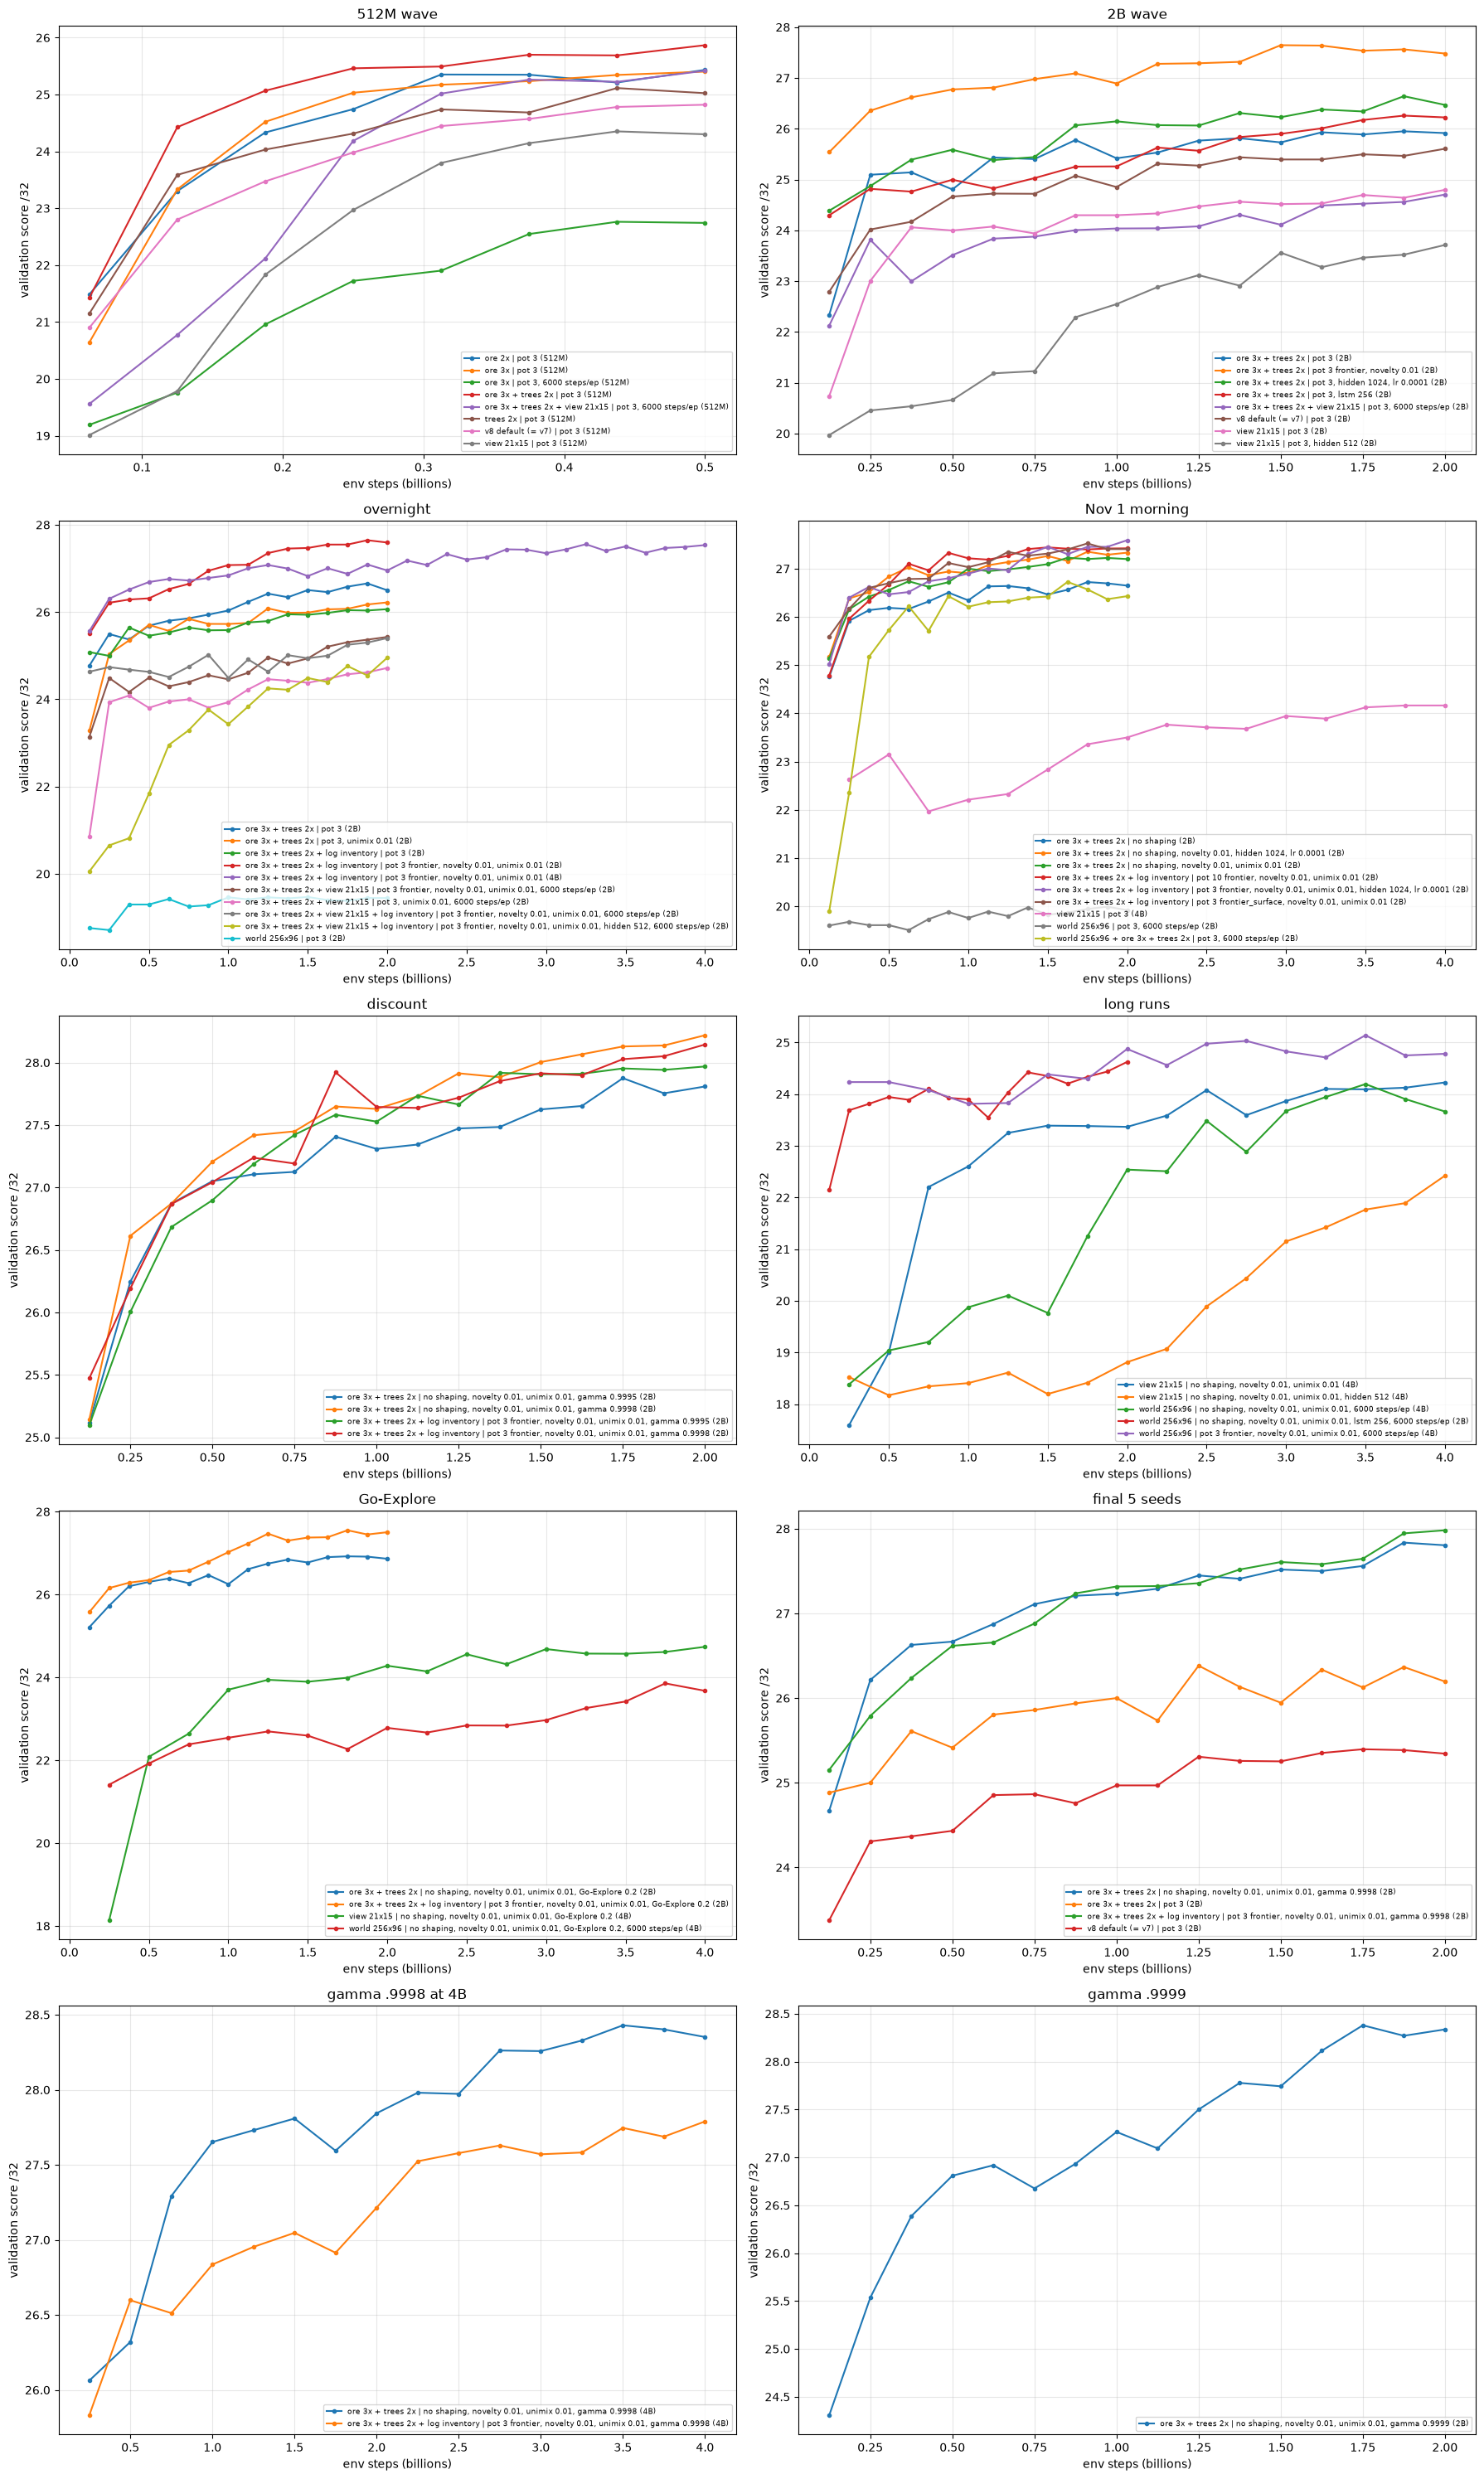

In [4]:
def plot(study, ax):
    sub = curves[curves.study == study]
    for (variant, arm, b), g in sub.groupby(["variant", "arm", "budget"]):
        m = g.groupby("steps_B").score.mean()
        ax.plot(m.index, m.values, marker=".", label=f"{variant} | {arm} ({b})")
    ax.set(title=study, xlabel="env steps (billions)", ylabel="validation score /32")
    ax.grid(alpha=.3)
    ax.legend(fontsize=6.5, loc="lower right")

ncols = 2
nrows = -(-len(STUDIES) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(9 * ncols, 6 * nrows), squeeze=False)
for study, ax in zip(STUDIES, axes.flat):
    plot(study, ax)
for ax in axes.flat[len(STUDIES):]:
    ax.set_visible(False)
plt.tight_layout()

## Hard achievements of the best arms (worlds out of 128, mean over seeds)

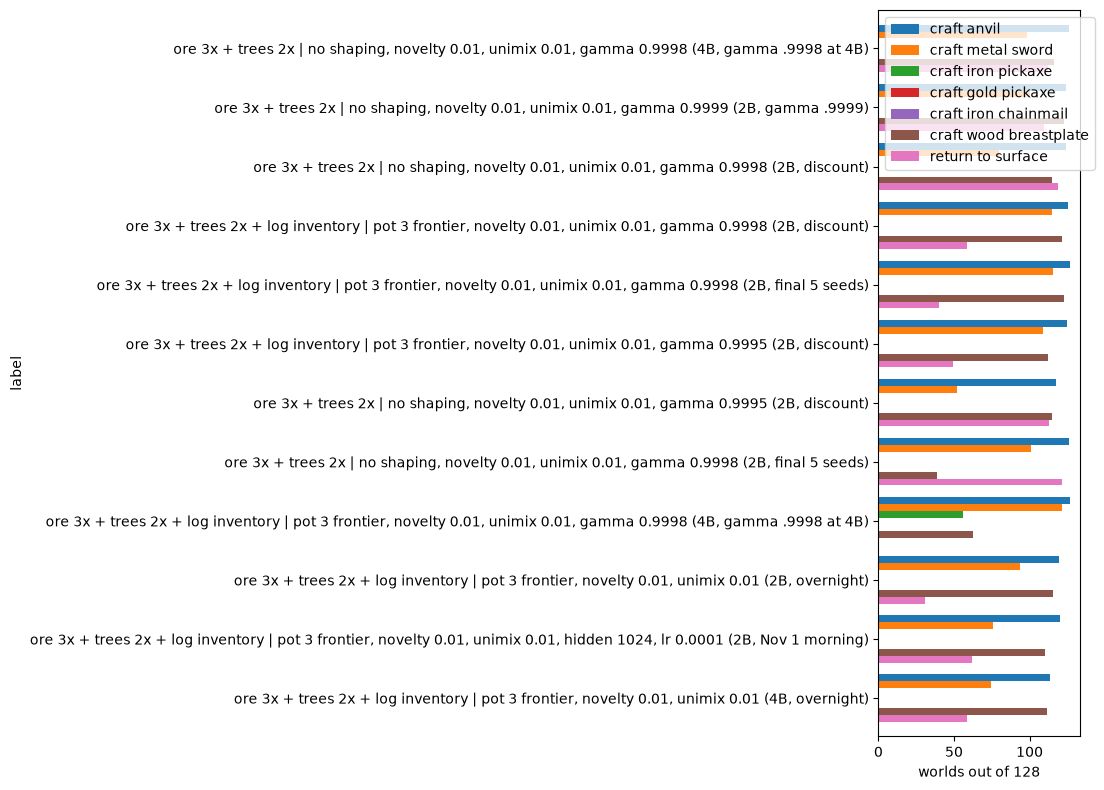

In [5]:
top = summary.reset_index().sort_values("score", ascending=False).head(12)
top = top.assign(label=top.variant + " | " + top.arm + " (" + top.budget + ", " + top.study + ")").set_index("label")
top[HARD].plot.barh(figsize=(11, 8), width=.8)
plt.xlabel("worlds out of 128")
plt.gca().invert_yaxis()
plt.tight_layout()

## Per-seed detail for one variant

Change `VARIANT` to inspect seed variance (return to surface differs a lot between seeds).

In [6]:
VARIANT = "ore 3x + trees 2x + log inventory"
runs[runs.variant == VARIANT].sort_values(["study", "arm", "seed"])[
    ["study", "arm", "budget", "seed", "steps_B", "score", *HARD, "iron_bars_med", "wood_med"]]

,study,arm,budget,seed,steps_B,score,craft anvil,craft metal sword,craft iron pickaxe,craft gold pickaxe,craft iron chainmail,craft wood breastplate,return to surface,iron_bars_med,wood_med
83,Go-Explore,"pot 3 frontier, novelty 0.01, unimix 0.01, Go-...",2B,2001,2.0,27.320312,125,71,0,0,0,113,9,5.0,41.0
84,Go-Explore,"pot 3 frontier, novelty 0.01, unimix 0.01, Go-...",2B,2002,2.0,27.687500,126,115,0,0,0,125,0,8.0,35.0
59,Nov 1 morning,"pot 10 frontier, novelty 0.01, unimix 0.01",2B,2001,2.0,28.000000,122,73,0,0,0,114,118,6.0,41.0
60,Nov 1 morning,"pot 10 frontier, novelty 0.01, unimix 0.01",2B,2002,2.0,26.843750,126,119,0,0,0,0,0,8.0,19.0
57,Nov 1 morning,"pot 3 frontier, novelty 0.01, unimix 0.01, hid...",2B,2001,2.0,27.632812,115,61,0,0,0,97,124,6.0,40.0
58,Nov 1 morning,"pot 3 frontier, novelty 0.01, unimix 0.01, hid...",2B,2002,2.0,27.546875,125,91,0,0,0,124,0,7.0,34.5
55,Nov 1 morning,"pot 3 frontier_surface, novelty 0.01, unimix 0.01",2B,2001,2.0,27.531250,106,53,0,0,0,102,121,5.0,42.0
56,Nov 1 morning,"pot 3 frontier_surface, novelty 0.01, unimix 0.01",2B,2002,2.0,27.281250,124,73,0,0,0,112,1,5.0,44.5
70,discount,"pot 3 frontier, novelty 0.01, unimix 0.01, gam...",2B,2001,2.0,28.281250,124,106,0,0,0,109,99,8.0,42.5
71,discount,"pot 3 frontier, novelty 0.01, unimix 0.01, gam...",2B,2002,2.0,27.656250,126,112,0,0,0,116,0,8.0,47.0


# Part 2: run catalogue and comparisons

## Every run and exactly how it differs

One row per run. Environment columns come from the library build (`variants/v8` knobs); training columns
come from the run's own `protocol.json`. Fixed for every run unless listed: PPO on the max-speed path,
1,024 envs x 128-step rollouts, 16 minibatches, entropy .03, GAE lambda .99, `targets` architecture
(per-cell MLP width 32, depth 2), bf16 + compile, 128 validation worlds.

In [7]:
catalogue_cols = ["study", "run", "seed", "budget", "steps_B", "hours", "finished",
                  # environment
                  "world", "ore %", "trunk %", "view", "log inventory", "episode_steps",
                  # training
                  "potential", "potential_mode", "novelty", "unimix", "go_explore", "gamma", "lr", "hidden", "memory", "params",
                  # results
                  "score", "best", "deaths", "idle_steps", *HARD,
                  "iron_bars_med", "iron_bars_max", "iron_bars_smelted_per_ep", "gold_bars_med", "wood_med",
                  "breastplate_legal_eps", "iron_pick_legal_eps"]
catalogue = runs[catalogue_cols].sort_values(["study", "world", "ore %", "view", "potential", "seed"]).reset_index(drop=True)
catalogue

,study,run,seed,budget,steps_B,hours,finished,world,ore %,trunk %,view,log inventory,episode_steps,potential,potential_mode,novelty,unimix,go_explore,gamma,lr,hidden,memory,params,score,best,deaths,idle_steps,craft anvil,craft metal sword,craft iron pickaxe,craft gold pickaxe,craft iron chainmail,craft wood breastplate,return to surface,iron_bars_med,iron_bars_max,iron_bars_smelted_per_ep,gold_bars_med,wood_med,breastplate_legal_eps,iron_pick_legal_eps
0,2B wave,build-v8-g0/pot_e1024_max2-2001,2001,2B,2.0,2.020534,True,128x96,100,100,11x9,False,3000,3.0,mean,0.00,0.00,0.0,0.999,0.0003,128,-,472718,25.718750,25.750000,0.062500,1498.789062,88,21,0,0,0,0,0,5.0,13.0,6.742188,2.0,13.0,0.0,0.0
1,2B wave,build-v8-g0/pot_e1024_max2-2002,2002,2B,2.0,2.013454,True,128x96,100,100,11x9,False,3000,3.0,mean,0.00,0.00,0.0,0.999,0.0003,128,-,472718,25.492188,25.492188,0.109375,1430.453125,82,19,0,0,0,0,1,5.0,12.0,6.460938,2.0,13.0,0.0,0.0
2,2B wave,build-v8-view21-g3/pot_e1024_max2-2001,2001,2B,2.0,2.625318,True,128x96,100,100,21x15,False,3000,3.0,mean,0.00,0.00,0.0,0.999,0.0003,128,-,1357454,24.718750,24.734375,0.187500,1512.804688,52,6,0,0,0,0,0,5.0,13.0,5.210938,2.0,13.0,0.0,0.0
3,2B wave,build-v8-view21-g4/ff_t512c32d2-2001,2001,2B,2.0,2.710327,True,128x96,100,100,21x15,False,3000,3.0,mean,0.00,0.00,0.0,0.999,0.0003,512,-,5551502,22.804688,22.804688,0.203125,1451.687500,31,7,0,0,0,0,0,3.0,11.0,3.398438,0.0,14.0,0.0,0.0
4,2B wave,build-v8-view21-g3/pot_e1024_max2-2002,2002,2B,2.0,2.646499,True,128x96,100,100,21x15,False,3000,3.0,mean,0.00,0.00,0.0,0.999,0.0003,128,-,1357454,24.875000,24.875000,0.148438,1462.164062,52,12,0,0,0,0,0,5.0,16.0,5.101562,1.0,13.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102,overnight,real_fn_unimix-2002/max2_fn_ep6000_unimix-2002,2002,2B,2.0,2.590412,True,128x96,300,200,21x15,False,6000,3.0,frontier,0.01,0.01,0.0,0.999,0.0003,128,-,1357454,25.945312,25.945312,0.335938,3154.242188,98,31,0,0,0,74,0,6.0,19.0,12.507812,4.0,39.0,103.0,0.0
103,overnight,real_unimix-2002/max2_ep6000_unimix-2002,2002,2B,2.0,2.463964,True,128x96,300,200,21x15,False,6000,3.0,mean,0.00,0.01,0.0,0.999,0.0003,128,-,1357454,25.062500,25.148438,0.312500,3458.875000,96,21,0,0,0,0,0,6.0,23.0,10.328125,3.0,29.5,2.0,0.0
104,overnight,realinv_fn_unimix-2002/max2_fn_ep6000_unimix-2002,2002,2B,2.0,2.576950,True,128x96,300,200,21x15,True,6000,3.0,frontier,0.01,0.01,0.0,0.999,0.0003,128,-,1361678,26.023438,26.023438,0.273438,3403.507812,109,50,0,0,0,53,0,6.0,20.0,14.320312,4.0,38.0,84.0,0.0
105,overnight,realinv_fn_unimix_h512-2002/max2_fn_ep6000_uni...,2002,2B,2.0,2.581132,True,128x96,300,200,21x15,True,6000,3.0,frontier,0.01,0.01,0.0,0.999,0.0003,512,-,5568398,24.867188,24.976562,0.273438,2911.453125,105,20,0,0,0,3,0,5.0,15.0,10.781250,2.0,33.0,60.0,0.0


## Comparisons along each dimension

Each table compares runs that differ in **one** dimension, holding the others as fixed as the data allows
(same budget, same arm or same environment). `delta` is the mean difference to the reference row.
Seeds are listed so seed noise (often 0.3-0.5 points) can be judged against the delta.

In [8]:
def compare(title, groups, ref):
    """groups: {label: boolean mask over runs}. Mean/std/seeds and key outcomes per label.
    Unfinished runs are included at their latest checkpoint (done < runs; their seeds are marked *)."""
    out = []
    for label, mask in groups.items():
        g = runs[mask]
        if g.empty:
            continue
        out.append(dict(setting=label, runs=len(g), done=int(g.finished.sum()),
                        seeds=", ".join(f"{s:.2f}" + ("" if f else "*") for s, f in zip(g.score, g.finished)),
                        score=g.score.mean(), score_sd=g.score.std(ddof=0), anvil=g["craft anvil"].mean(),
                        breastplate=g["craft wood breastplate"].mean(), surface=g["return to surface"].mean(),
                        iron_pick=g["craft iron pickaxe"].mean(), iron_bars_med=g.iron_bars_med.mean(),
                        wood_med=g.wood_med.mean(), deaths=g.deaths.mean(), hours=g.hours.mean()))
    t = pd.DataFrame(out).set_index("setting")
    if ref in t.index:
        t.insert(4, "delta", t.score - t.loc[ref, "score"])
    print(title)
    return t.round(2)

v = runs
std = (v.potential == 3) & (v.potential_mode == "mean") & (v.novelty == 0) & (v.unimix == 0) & (v.go_explore == 0) \
      & (v.memory == "-") & (v.hidden == 128) & (v.gamma == 0.999) & (v.lr == 3e-4)
std3k = std & (v.episode_steps == 3000)

In [9]:
# 1. Resource supply (standard arm, 3,000-step episodes, 11x9 view, 128-wide world)
base_env = (v.view == "11x9") & (v.world == "128x96") & ~v["log inventory"].astype(bool)
display(compare("Supply at 512M", {
    "v8 default": std3k & base_env & (v["ore %"] == 100) & (v["trunk %"] == 100) & (v.budget == "512M"),
    "ore 2x": std3k & base_env & (v["ore %"] == 200) & (v["trunk %"] == 100) & (v.budget == "512M"),
    "ore 3x": std3k & base_env & (v["ore %"] == 300) & (v["trunk %"] == 100) & (v.budget == "512M"),
    "trees 2x": std3k & base_env & (v["ore %"] == 100) & (v["trunk %"] == 200) & (v.budget == "512M"),
    "ore 3x + trees 2x": std3k & base_env & (v["ore %"] == 300) & (v["trunk %"] == 200) & (v.budget == "512M"),
}, ref="v8 default"))
display(compare("Supply at 2B", {
    "v8 default": std3k & base_env & (v["ore %"] == 100) & (v.budget == "2B"),
    "ore 3x + trees 2x": std3k & base_env & (v["ore %"] == 300) & (v["trunk %"] == 200) & (v.budget == "2B"),
}, ref="v8 default"))

Supply at 512M


,runs,done,seeds,score,delta,score_sd,anvil,breastplate,surface,iron_pick,iron_bars_med,wood_med,deaths,hours
setting,,,,,,,,,,,,,,
v8 default,2,2,"24.95, 24.69",24.82,0.00,0.13,55.5,0.0,0.0,0.0,5.0,13.0,0.10,0.51
ore 2x,2,2,"25.58, 25.29",25.43,0.61,0.14,91.5,0.0,0.0,0.0,5.0,13.0,0.10,0.50
ore 3x,2,2,"25.13, 25.67",25.40,0.58,0.27,99.5,0.0,0.0,0.0,5.0,13.0,0.10,0.50
trees 2x,2,2,"24.90, 25.15",25.02,0.20,0.12,52.5,0.0,0.0,0.0,4.5,17.0,0.10,0.51
ore 3x + trees 2x,2,2,"26.09, 25.65",25.87,1.05,0.22,102.0,0.0,43.5,0.0,5.0,17.5,0.09,0.51


Supply at 2B


,runs,done,seeds,score,delta,score_sd,anvil,breastplate,surface,iron_pick,iron_bars_med,wood_med,deaths,hours
setting,,,,,,,,,,,,,,
v8 default,5,5,"25.72, 25.49, 25.26, 25.34, 25.44",25.45,0.00,0.16,78.0,0.0,0.2,0.0,5.0,13.2,0.09,1.99
ore 3x + trees 2x,5,5,"25.72, 26.11, 26.55, 26.45, 26.20",26.20,0.76,0.29,105.0,0.0,72.8,0.0,5.0,17.5,0.05,2.04


In [10]:
# 2. Reward shaping and generic exploration on ore 3x + trees 2x (2B, gamma .999, 128 hidden, no memory)
o3t2 = (v["ore %"] == 300) & (v["trunk %"] == 200) & (v.view == "11x9") & (v.world == "128x96") & (v.budget == "2B") \
       & (v.gamma == 0.999) & (v.memory == "-") & (v.episode_steps == 3000) & (v.go_explore == 0)
h128 = v.hidden == 128
inv = v["log inventory"].astype(bool)
display(compare("Shaping / exploration aids (ore 3x + trees 2x, 2B)", {
    "pot 3 mean (standard)": o3t2 & ~inv & std,
    "no shaping": o3t2 & ~inv & h128 & (v.potential == 0) & (v.novelty == 0) & (v.unimix == 0),
    "no shaping + novelty + unimix": o3t2 & ~inv & h128 & (v.potential == 0) & (v.novelty > 0) & (v.unimix > 0),
    "pot 3 mean + unimix": o3t2 & ~inv & h128 & (v.potential == 3) & (v.potential_mode == "mean") & (v.unimix > 0),
    "frontier + novelty": o3t2 & ~inv & h128 & (v.potential_mode == "frontier") & (v.unimix == 0),
    "log inv + pot 3 mean": o3t2 & inv & std,
    "log inv + frontier + novelty + unimix": o3t2 & inv & h128 & (v.potential == 3) & (v.potential_mode == "frontier") & (v.unimix > 0),
    "log inv + frontier coef 10": o3t2 & inv & h128 & (v.potential == 10),
    "log inv + frontier_surface": o3t2 & inv & h128 & (v.potential_mode == "frontier_surface"),
}, ref="pot 3 mean (standard)"))

Shaping / exploration aids (ore 3x + trees 2x, 2B)


,runs,done,seeds,score,delta,score_sd,anvil,breastplate,surface,iron_pick,iron_bars_med,wood_med,deaths,hours
setting,,,,,,,,,,,,,,
pot 3 mean (standard),5,5,"25.72, 26.11, 26.55, 26.45, 26.20",26.20,0.00,0.29,105.00,0.00,72.8,0.0,5.00,17.50,0.05,2.04
no shaping,2,2,"26.39, 26.91",26.65,0.44,0.26,101.00,115.00,0.5,0.0,5.00,40.00,0.10,1.74
no shaping + novelty + unimix,2,2,"27.35, 27.05",27.20,0.99,0.15,104.50,111.50,59.5,0.0,5.00,44.00,0.06,1.92
pot 3 mean + unimix,4,4,"25.98, 26.51, 26.28, 26.12",26.22,0.02,0.20,118.75,0.00,0.0,0.0,6.62,17.62,0.09,2.15
frontier + novelty,2,2,"27.36, 27.60",27.48,1.28,0.12,108.00,104.00,115.0,0.0,5.00,42.00,0.04,2.20
log inv + pot 3 mean,2,2,"26.16, 25.97",26.07,-0.14,0.10,107.50,0.00,62.0,0.0,5.00,17.25,0.09,2.06
log inv + frontier + novelty + unimix,4,4,"27.47, 27.72, 27.61, 27.58",27.59,1.39,0.09,119.50,115.25,30.5,0.0,7.50,41.88,0.05,2.30
log inv + frontier coef 10,2,2,"28.00, 26.84",27.42,1.22,0.58,124.00,57.00,59.0,0.0,7.00,30.00,0.02,2.24
log inv + frontier_surface,2,2,"27.53, 27.28",27.41,1.20,0.12,115.00,107.00,61.0,0.0,5.00,43.25,0.04,2.36


In [11]:
# 3. Discount horizon (ore 3x + trees 2x, 2B)
best_arm = inv & (v.potential == 3) & (v.potential_mode == "frontier") & (v.unimix > 0) & (v.hidden == 128) & (v.go_explore == 0)
gen_arm = ~inv & (v.potential == 0) & (v.novelty > 0) & (v.unimix > 0) & (v.hidden == 128) & (v.go_explore == 0)
cond = (v["ore %"] == 300) & (v.world == "128x96") & (v.view == "11x9") & (v.budget == "2B") & (v.memory == "-")
display(compare("Discount: best shaped arm", {f"gamma {g:g}": cond & best_arm & (v.gamma == g) for g in (0.999, 0.9995, 0.9998)},
                ref="gamma 0.999"))
display(compare("Discount: generic arm (no shaping)", {f"gamma {g:g}": cond & gen_arm & (v.gamma == g) for g in (0.999, 0.9995, 0.9998)},
                ref="gamma 0.999"))

Discount: best shaped arm


,runs,done,seeds,score,delta,score_sd,anvil,breastplate,surface,iron_pick,iron_bars_med,wood_med,deaths,hours
setting,,,,,,,,,,,,,,
gamma 0.999,4,4,"27.47, 27.72, 27.61, 27.58",27.59,0.00,0.09,119.5,115.25,30.5,0.0,7.5,41.88,0.05,2.30
gamma 0.9995,2,2,"28.28, 27.66",27.97,0.38,0.31,125.0,112.50,49.5,0.0,8.0,44.75,0.04,2.16
gamma 0.9998,5,5,"28.59, 27.70, 27.66, 27.74, 28.54",28.05,0.45,0.42,126.4,122.40,47.4,0.0,8.0,41.40,0.01,2.20


Discount: generic arm (no shaping)


,runs,done,seeds,score,delta,score_sd,anvil,breastplate,surface,iron_pick,iron_bars_med,wood_med,deaths,hours
setting,,,,,,,,,,,,,,
gamma 0.999,2,2,"27.35, 27.05",27.20,0.00,0.15,104.5,111.5,59.5,0.0,5.0,44.0,0.06,1.92
gamma 0.9995,2,2,"27.59, 28.02",27.81,0.61,0.21,117.5,115.0,113.0,0.0,5.0,47.5,0.02,1.87
gamma 0.9998,5,5,"28.17, 28.27, 27.58, 28.41, 27.43",27.97,0.77,0.39,125.2,69.2,120.2,0.0,6.2,35.9,0.01,1.83


In [12]:
# 4. Model capacity and memory
display(compare("Capacity / memory on ore 3x + trees 2x (2B)", {
    "standard (hidden 128)": o3t2 & ~inv & std,
    "hidden 1024, lr 1e-4": o3t2 & ~inv & (v.potential == 3) & (v.potential_mode == "mean") & (v.hidden == 1024),
    "LSTM 256": (v["ore %"] == 300) & (v["trunk %"] == 200) & (v.budget == "2B") & (v.memory == "lstm"),
    "generic arm, hidden 128": o3t2 & gen_arm,
    "generic arm, hidden 1024": o3t2 & ~inv & (v.potential == 0) & (v.hidden == 1024),
    "best shaped arm, hidden 128": o3t2 & best_arm,
    "best shaped arm, hidden 1024": o3t2 & inv & (v.potential_mode == "frontier") & (v.hidden == 1024),
}, ref="standard (hidden 128)"))

Capacity / memory on ore 3x + trees 2x (2B)


,runs,done,seeds,score,delta,score_sd,anvil,breastplate,surface,iron_pick,iron_bars_med,wood_med,deaths,hours
setting,,,,,,,,,,,,,,
standard (hidden 128),5,5,"25.72, 26.11, 26.55, 26.45, 26.20",26.20,0.00,0.29,105.0,0.00,72.8,0.0,5.0,17.50,0.05,2.04
"hidden 1024, lr 1e-4",2,2,"26.28, 26.66",26.47,0.26,0.19,103.5,0.00,120.5,0.0,5.0,17.50,0.03,2.09
LSTM 256,2,2,"26.16, 26.28",26.22,0.02,0.06,98.0,0.00,116.5,0.0,5.0,19.50,0.02,4.50
"generic arm, hidden 128",2,2,"27.35, 27.05",27.20,0.99,0.15,104.5,111.50,59.5,0.0,5.0,44.00,0.06,1.92
"generic arm, hidden 1024",2,2,"27.09, 27.57",27.33,1.13,0.24,102.5,113.50,120.5,0.0,5.0,38.50,0.02,1.92
"best shaped arm, hidden 128",4,4,"27.47, 27.72, 27.61, 27.58",27.59,1.39,0.09,119.5,115.25,30.5,0.0,7.5,41.88,0.05,2.30
"best shaped arm, hidden 1024",2,2,"27.63, 27.55",27.59,1.39,0.04,120.0,110.50,62.0,0.0,6.5,37.25,0.02,2.29


In [13]:
# 5. Larger world and larger view (all budgets; default supply unless stated)
display(compare("Larger world", {
    "128x96, standard, 2B": std3k & base_env & (v["ore %"] == 100) & (v.budget == "2B"),
    "256x96, standard, 2B": std3k & (v.world == "256x96") & (v["ore %"] == 100),
    "256x96, standard, 6000 steps/ep, 2B": std & (v.world == "256x96") & (v["ore %"] == 100) & (v.episode_steps == 6000),
    "256x96, generic arm, 6000 steps/ep, 4B": (v.world == "256x96") & (v["ore %"] == 100) & (v.potential == 0) & (v.memory == "-") & (v.go_explore == 0),
    "256x96, frontier arm, 6000 steps/ep, 4B": (v.world == "256x96") & (v["ore %"] == 100) & (v.potential_mode == "frontier"),
    "256x96, generic + LSTM, 6000 steps/ep, 2B": (v.world == "256x96") & (v.memory == "lstm"),
    "256x96, generic + Go-Explore": (v.world == "256x96") & (v.go_explore > 0),
    "256x96 + ore 3x + trees 2x, 6000 steps/ep, 2B": (v.world == "256x96") & (v["ore %"] == 300),
}, ref="128x96, standard, 2B"))
display(compare("Larger view (default supply)", {
    "11x9, standard, 2B": std3k & base_env & (v["ore %"] == 100) & (v.budget == "2B"),
    "21x15, standard, 2B": std3k & (v.view == "21x15") & (v["ore %"] == 100) & (v.budget == "2B"),
    "21x15, standard, 4B": std3k & (v.view == "21x15") & (v["ore %"] == 100) & (v.budget == "4B"),
    "21x15, hidden 512, 2B": (v.view == "21x15") & (v["ore %"] == 100) & (v.hidden == 512) & (v.potential == 3),
    "21x15, generic arm, 4B": (v.view == "21x15") & (v["ore %"] == 100) & (v.potential == 0) & (v.hidden == 128) & (v.go_explore == 0),
    "21x15, generic arm + hidden 512, 4B": (v.view == "21x15") & (v["ore %"] == 100) & (v.potential == 0) & (v.hidden == 512),
    "21x15, generic + Go-Explore, 4B": (v.view == "21x15") & (v.go_explore > 0),
}, ref="11x9, standard, 2B"))

Larger world


,runs,done,seeds,score,delta,score_sd,anvil,breastplate,surface,iron_pick,iron_bars_med,wood_med,deaths,hours
setting,,,,,,,,,,,,,,
"128x96, standard, 2B",5,5,"25.72, 25.49, 25.26, 25.34, 25.44",25.45,0.00,0.16,78.0,0.0,0.2,0.0,5.0,13.2,0.09,1.99
"256x96, standard, 2B",1,1,19.45,19.45,-6.00,0.00,0.0,0.0,0.0,0.0,0.0,12.0,0.08,2.21
"256x96, standard, 6000 steps/ep, 2B",1,1,19.92,19.92,-5.53,0.00,0.0,0.0,18.0,0.0,0.0,12.0,0.04,2.10
"256x96, generic arm, 6000 steps/ep, 4B",1,1,23.66,23.66,-1.78,0.00,38.0,0.0,1.0,0.0,4.0,15.0,0.31,3.63
"256x96, frontier arm, 6000 steps/ep, 4B",1,1,24.78,24.78,-0.67,0.00,43.0,94.0,0.0,0.0,4.0,38.0,0.26,4.30
"256x96, generic + LSTM, 6000 steps/ep, 2B",1,1,24.62,24.62,-0.82,0.00,39.0,64.0,0.0,0.0,5.0,36.0,0.23,3.95
"256x96, generic + Go-Explore",2,2,"21.53, 25.82",23.68,-1.77,2.14,22.0,57.0,0.0,0.0,3.0,27.0,0.21,4.30
"256x96 + ore 3x + trees 2x, 6000 steps/ep, 2B",1,1,26.43,26.43,0.98,0.00,83.0,128.0,1.0,0.0,5.0,37.0,0.14,1.98


Larger view (default supply)


,runs,done,seeds,score,delta,score_sd,anvil,breastplate,surface,iron_pick,iron_bars_med,wood_med,deaths,hours
setting,,,,,,,,,,,,,,
"11x9, standard, 2B",5,5,"25.72, 25.49, 25.26, 25.34, 25.44",25.45,0.00,0.16,78.0,0.0,0.2,0.0,5.0,13.2,0.09,1.99
"21x15, standard, 2B",2,2,"24.72, 24.88",24.80,-0.65,0.08,52.0,0.0,0.0,0.0,5.0,13.0,0.17,2.64
"21x15, standard, 4B",1,1,24.16,24.16,-1.28,0.00,21.0,0.0,0.0,0.0,NaN,NaN,0.20,4.43
"21x15, hidden 512, 2B",2,2,"22.80, 24.62",23.71,-1.74,0.91,41.5,0.0,0.0,0.0,3.5,13.5,0.21,2.73
"21x15, generic arm, 4B",1,1,24.23,24.23,-1.22,0.00,23.0,0.0,0.0,0.0,4.0,14.0,0.19,4.15
"21x15, generic arm + hidden 512, 4B",1,1,22.42,22.42,-3.03,0.00,13.0,0.0,0.0,0.0,2.0,13.0,0.23,4.23
"21x15, generic + Go-Explore, 4B",2,2,"24.69, 24.79",24.74,-0.71,0.05,47.0,0.0,0.0,0.0,4.5,15.0,0.12,4.78


In [14]:
# 6. Training budget: same arm at 512M / 2B / 4B
display(compare("Budget", {
    "ore 3x + trees 2x, standard, 512M": std3k & base_env & (v["ore %"] == 300) & (v["trunk %"] == 200) & (v.budget == "512M"),
    "ore 3x + trees 2x, standard, 2B": std3k & base_env & (v["ore %"] == 300) & (v["trunk %"] == 200) & (v.budget == "2B"),
    "best shaped arm, 2B": cond & best_arm & (v.gamma == 0.999),
    "best shaped arm, 4B": (v["ore %"] == 300) & best_arm & (v.budget == "4B") & (v.gamma == 0.999),
}, ref="ore 3x + trees 2x, standard, 2B"))

Budget


,runs,done,seeds,score,delta,score_sd,anvil,breastplate,surface,iron_pick,iron_bars_med,wood_med,deaths,hours
setting,,,,,,,,,,,,,,
"ore 3x + trees 2x, standard, 512M",2,2,"26.09, 25.65",25.87,-0.34,0.22,102.0,0.00,43.5,0.0,5.0,17.50,0.09,0.51
"ore 3x + trees 2x, standard, 2B",5,5,"25.72, 26.11, 26.55, 26.45, 26.20",26.20,0.00,0.29,105.0,0.00,72.8,0.0,5.0,17.50,0.05,2.04
"best shaped arm, 2B",4,4,"27.47, 27.72, 27.61, 27.58",27.59,1.39,0.09,119.5,115.25,30.5,0.0,7.5,41.88,0.05,2.30
"best shaped arm, 4B",2,2,"27.68, 27.39",27.54,1.33,0.14,113.5,111.50,58.5,0.0,6.5,39.25,0.02,4.43


In [15]:
# 7. Go-Explore vs the same arm without it (in progress)
display(compare("Go-Explore restarts (20% of training episodes)", {
    "generic arm, ore 3x + trees 2x": o3t2 & gen_arm & (v.gamma == 0.999),
    "generic arm + Go-Explore": (v["ore %"] == 300) & (v.world == "128x96") & ~inv & (v.potential == 0) & (v.go_explore > 0),
    "best shaped arm": cond & best_arm & (v.gamma == 0.999),
    "best shaped arm + Go-Explore": (v["ore %"] == 300) & inv & (v.potential_mode == "frontier") & (v.go_explore > 0),
}, ref="generic arm, ore 3x + trees 2x"))

Go-Explore restarts (20% of training episodes)


,runs,done,seeds,score,delta,score_sd,anvil,breastplate,surface,iron_pick,iron_bars_med,wood_med,deaths,hours
setting,,,,,,,,,,,,,,
"generic arm, ore 3x + trees 2x",2,2,"27.35, 27.05",27.20,0.00,0.15,104.5,111.50,59.5,0.0,5.0,44.00,0.06,1.92
generic arm + Go-Explore,2,2,"26.71, 27.02",26.86,-0.34,0.15,113.5,108.50,0.0,0.0,5.0,42.00,0.03,2.12
best shaped arm,4,4,"27.47, 27.72, 27.61, 27.58",27.59,0.39,0.09,119.5,115.25,30.5,0.0,7.5,41.88,0.05,2.30
best shaped arm + Go-Explore,2,2,"27.32, 27.69",27.50,0.30,0.18,125.5,119.00,4.5,0.0,6.5,38.00,0.05,2.45


## Training health by discount factor

PPO does not log its loss values; each checkpoint records the last update's policy entropy, approximate
KL, clip fraction and value explained variance (`curve.json` -> `profile`). One line per seed.

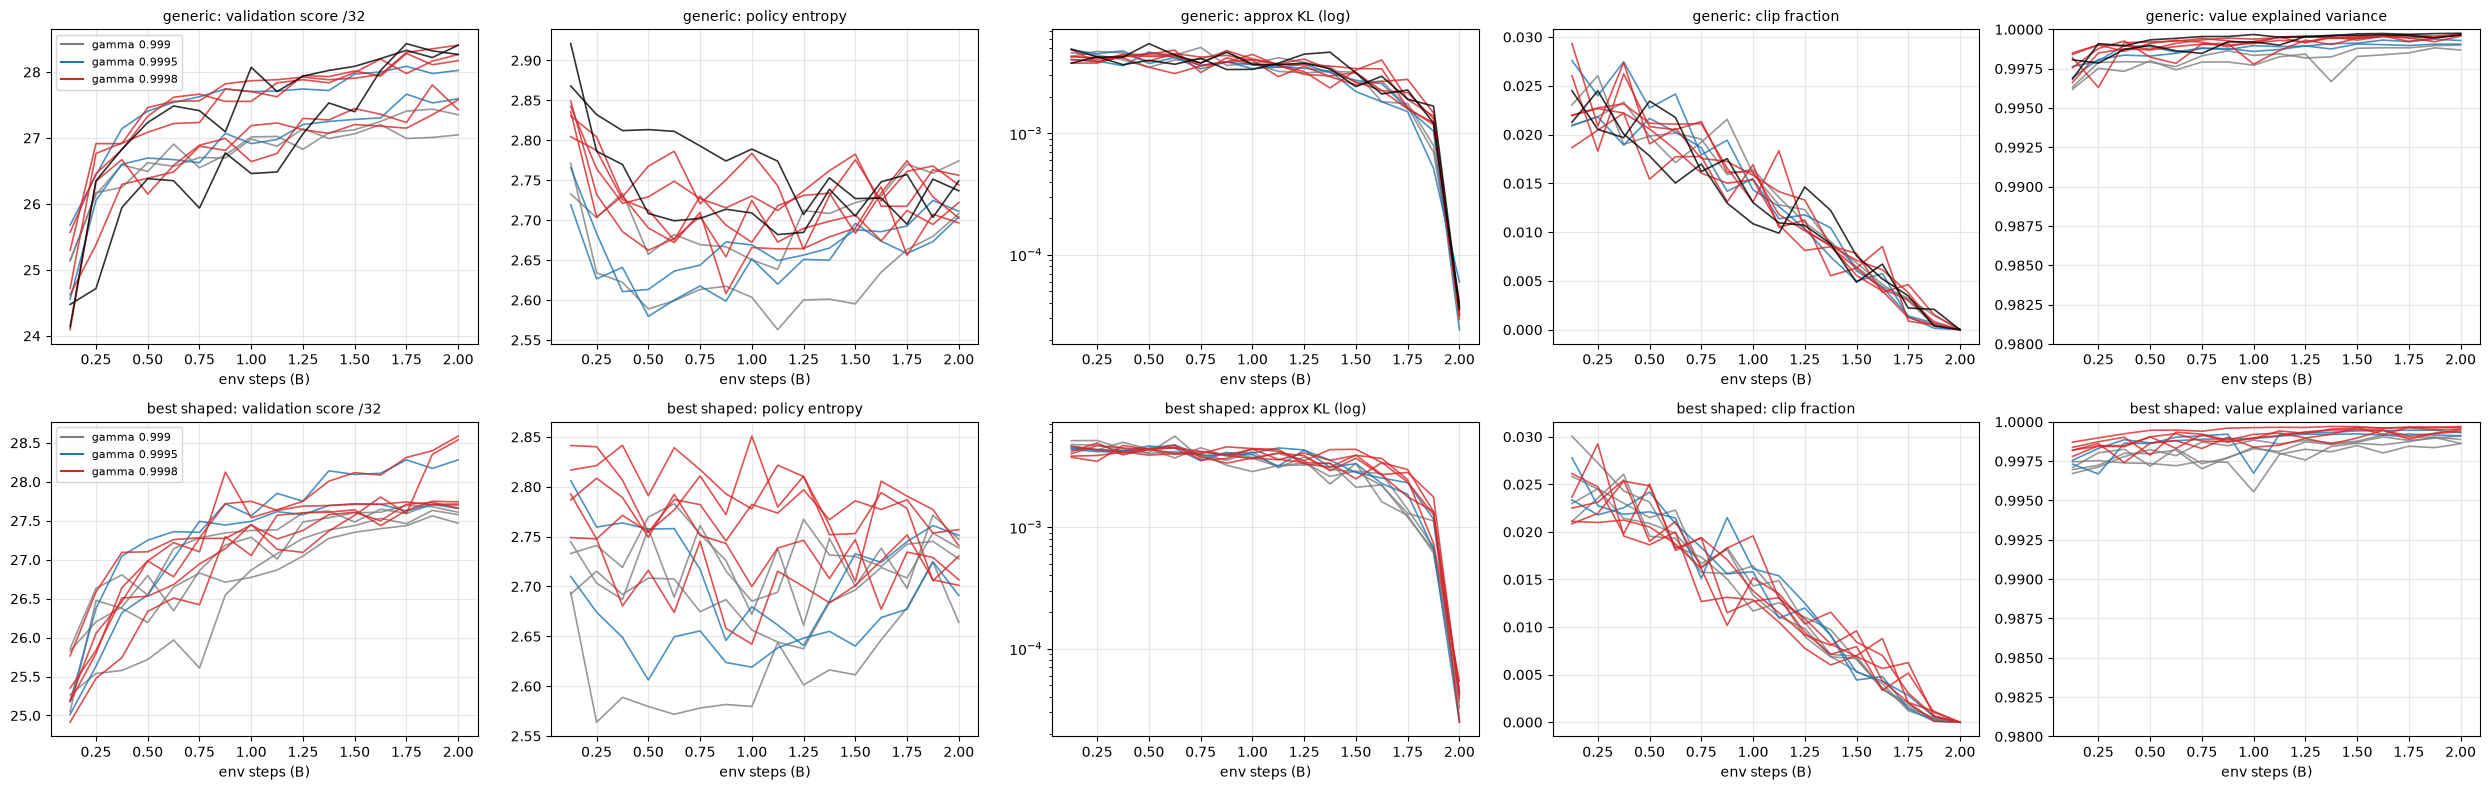

In [16]:
metrics = [("score", "validation score /32"), ("policy_entropy", "policy entropy"), ("approx_kl", "approx KL (log)"),
           ("clip_fraction", "clip fraction"), ("explained_variance", "value explained variance")]
colors = {0.999: "tab:gray", 0.9995: "tab:blue", 0.9998: "tab:red"}
gmask = (v["ore %"] == 300) & (v.world == "128x96") & (v.view == "11x9") & (v.budget == "2B") & (v.memory == "-") & (v.go_explore == 0)
fig, axes = plt.subplots(2, len(metrics), figsize=(5 * len(metrics), 8))
for row, (arm, mask) in enumerate({"generic": gmask & gen_arm, "best shaped": gmask & best_arm}.items()):
    for _, r in runs[mask].iterrows():
        study_dir = DATA / STUDIES[r.study]
        group, name = r.run.split("/")
        curve = json.loads((study_dir / group / "runs" / name / "curve.json").read_text())
        x = [c["steps"] / 2**30 for c in curve]
        for col, (m, label) in enumerate(metrics):
            y = [c["evaluation"]["mean_achievements"] if m == "score" else c["profile"][m] for c in curve]
            axes[row, col].plot(x, y, color=colors.get(r.gamma, "k"), alpha=.8, lw=1.2)
    for col, (m, label) in enumerate(metrics):
        ax = axes[row, col]
        ax.set_title(f"{arm}: {label}", fontsize=10); ax.grid(alpha=.3); ax.set_xlabel("env steps (B)")
        if m == "approx_kl": ax.set_yscale("log")
        if m == "explained_variance": ax.set_ylim(0.98, 1.0)
    for g, c in colors.items():
        axes[row, 0].plot([], [], color=c, label=f"gamma {g}")
    axes[row, 0].legend(fontsize=8)
plt.tight_layout()

# Part 3: statistics for the final configurations

Convention for deep-RL comparisons (Agarwal et al. 2021, `rliable`): report the interquartile mean (IQM)
over seeds with a bootstrapped 95% confidence interval, plus the probability of improvement
P(X > Y) = chance a random seed of X beats a random seed of Y. Final checkpoints only; validation worlds.
The Crafter score is Crafter's geometric-mean metric over all 32 achievements, which rewards rare
achievements much more than the mean count.

In [17]:
import numpy as np
rng = np.random.default_rng(0)

def iqm(x):
    x = np.sort(np.asarray(x, float)); n = len(x)
    k = int(np.floor(0.25 * n))
    return x[k:n - k].mean() if n - 2 * k > 0 else x.mean()

def boot_ci(x, stat=iqm, n=10000):
    x = np.asarray(x, float)
    s = [stat(rng.choice(x, len(x))) for _ in range(n)]
    return np.percentile(s, [2.5, 97.5])

def p_improve(x, y):
    x, y = np.asarray(x)[:, None], np.asarray(y)[None, :]
    return float((x > y).mean() + 0.5 * (x == y).mean())

FINAL = {
    "v8 default (= v7), standard": std3k & base_env & (v["ore %"] == 100) & (v.budget == "2B"),
    "ore 3x + trees 2x, standard": std3k & base_env & (v["ore %"] == 300) & (v["trunk %"] == 200) & (v.budget == "2B"),
    "ore 3x + trees 2x, generic, gamma .9998": (v["ore %"] == 300) & (v.world == "128x96") & (v.view == "11x9") & (v.budget == "2B") & gen_arm & (v.gamma == 0.9998),
    "ore 3x + trees 2x + log inv, best shaped, gamma .9998": (v["ore %"] == 300) & (v.world == "128x96") & (v.view == "11x9") & (v.budget == "2B") & best_arm & (v.gamma == 0.9998),
}
table = []
for name, mask in FINAL.items():
    g = runs[mask & runs.finished]
    if g.empty:
        continue
    lo, hi = boot_ci(g.score)
    clo, chi = boot_ci(g.crafter_score)
    t = g.test_score.dropna() if "test_score" in g else pd.Series(dtype=float)
    tlo, thi = boot_ci(t) if len(t) else (np.nan, np.nan)
    table.append(dict(config=name, seeds=len(g), scores=", ".join(f"{s:.2f}" for s in sorted(g.score)),
                      mean=g.score.mean(), IQM=iqm(g.score), ci_low=lo, ci_high=hi,
                      crafter_score=g.crafter_score.mean(), crafter_ci=f"[{clo:.1f}, {chi:.1f}]",
                      surface_runs_over_100=int((g["return to surface"] > 100).sum()),
                      test_seeds=len(t), test_IQM=iqm(t) if len(t) else np.nan, test_ci_low=tlo, test_ci_high=thi,
                      test_crafter=g.test_crafter_score.mean() if "test_crafter_score" in g else np.nan))
final_table = pd.DataFrame(table).set_index("config").round(2)
final_table

,seeds,scores,mean,IQM,ci_low,ci_high,crafter_score,crafter_ci,surface_runs_over_100,test_seeds,test_IQM,test_ci_low,test_ci_high,test_crafter
config,,,,,,,,,,,,,,
"v8 default (= v7), standard",5,"25.26, 25.34, 25.44, 25.49, 25.72",25.45,25.42,25.28,25.64,44.28,"[43.6, 45.0]",0,5,25.38,25.30,25.53,44.31
"ore 3x + trees 2x, standard",5,"25.72, 26.11, 26.20, 26.45, 26.55",26.20,26.25,25.85,26.52,49.08,"[45.9, 51.7]",3,5,26.28,25.95,26.56,49.31
"ore 3x + trees 2x, generic, gamma .9998",5,"27.43, 27.58, 28.17, 28.27, 28.41",27.97,28.01,27.48,28.36,59.67,"[54.8, 63.1]",5,5,28.00,27.51,28.33,59.68
"ore 3x + trees 2x + log inv, best shaped, gamma .9998",5,"27.66, 27.70, 27.74, 28.54, 28.59",28.05,27.99,27.68,28.57,58.96,"[55.5, 63.6]",2,5,27.98,27.72,28.50,58.54


In [18]:
names = list(FINAL)
groups = {n: runs[FINAL[n] & runs.finished].score.values for n in names}
pairs = [(a, b) for a in names for b in names if a != b and len(groups[a]) and len(groups[b])]
pd.DataFrame([dict(X=a, Y=b, P_X_beats_Y=round(p_improve(groups[a], groups[b]), 2)) for a, b in pairs]).pivot(index="X", columns="Y", values="P_X_beats_Y")

Y,"ore 3x + trees 2x + log inv, best shaped, gamma .9998","ore 3x + trees 2x, generic, gamma .9998","ore 3x + trees 2x, standard","v8 default (= v7), standard"
X,,,,
"ore 3x + trees 2x + log inv, best shaped, gamma .9998",NaN,0.64,1.00,1.00
"ore 3x + trees 2x, generic, gamma .9998",0.36,NaN,1.00,1.00
"ore 3x + trees 2x, standard",0.00,0.00,NaN,0.98
"v8 default (= v7), standard",0.00,0.00,0.02,NaN


## Score against compute (GPU-hours per run; 2 runs shared a GPU unless noted in the study)

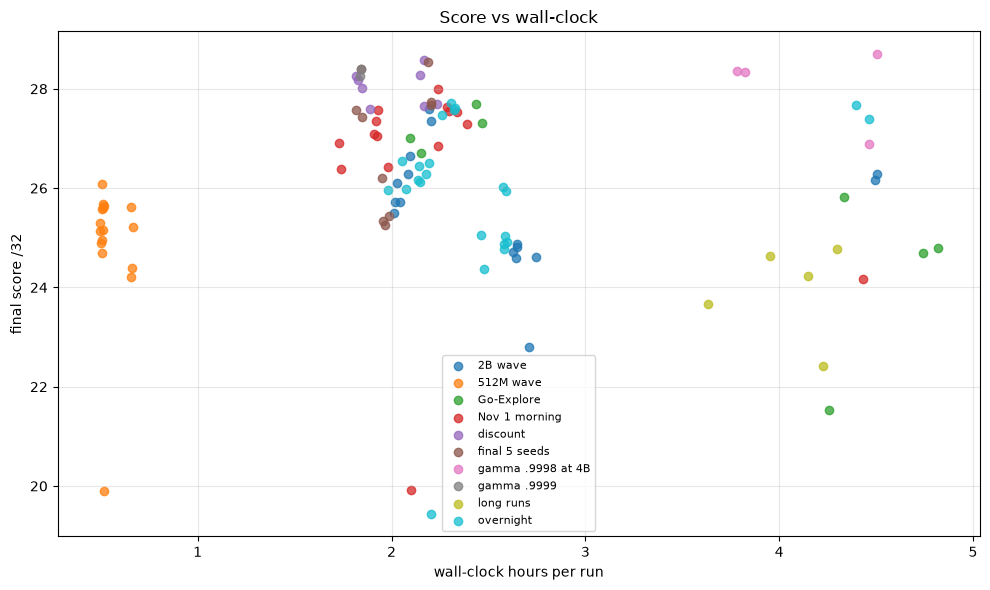

In [19]:
fin = runs[runs.finished]
fig, ax = plt.subplots(figsize=(10, 6))
for study, g in fin.groupby("study"):
    ax.scatter(g.hours, g.score, label=study, alpha=.75)
ax.set(xlabel="wall-clock hours per run", ylabel="final score /32", title="Score vs wall-clock")
ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout()